<div style="
border-left:8px solid #2e8b57;
padding:12px;
background:#f4fff7;
font-size:28px;
font-weight:bold;
color:#2e8b57">

Comment Category Prediction Challenge  
MLP Project – IITM BS in Data Science

</div>

<div style="
border-left:8px solid #2e8b57;
padding:12px;
background:#f4fff7;
/* font-size:15px; */
font-weight:bold;
color:#2e8b57">

# 1. Introduction

</div>

<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## 1.1 Project Objective

</div>

<div style="
border-left:8px solid #2e8b57;
padding:18px;
font-size:18px;
line-height:1.7;
color:white;
max-width:850px;
">
The objective of this project is to analyze the dataset and build machine learning models that can accurately predict the <b>final category of each comment</b>.

<br>

By exploring textual data and extracting meaningful features, we aim to identify patterns that help classify comments into their correct categories. Multiple models will be trained and compared to select the most effective approach for this classification task.

</div>

<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## 1.2 Dataset overview

</div>

<div style="
border-left:8px solid #2e8b57;
padding:18px;
font-size:18px;
line-height:1.7;
color:white;
max-width:900px;
">

<b style="font-size:22px;">Dataset Overview</b>

<br>

<b>Data Files</b>

<ul>
<li><b>train.csv</b> – The training dataset containing all feature columns along with the target variable <b>label</b>.</li>
<li><b>test.csv</b> – The test dataset containing the same feature columns but without the target variable.</li>
<li><b>sample_submission.csv</b> – A sample file showing the correct format for submitting predictions in the competition.</li>
</ul>

<br>

<b>Column Description</b>

<ul>
<li><b>comment</b> – Raw textual content of the user comment.</li>

<li><b>created_date</b> – Date and time when the comment was posted.</li>

<li><b>post_id</b> – Unique identifier linking the comment to its discussion thread.</li>

<li><b>emoticon_1</b>, <b>emoticon_2</b>, <b>emoticon_3</b> – Indicators showing the presence of emoticons from three internal emoticon groups.</li>

<li><b>upvote</b> – Number of positive reactions received by the comment.</li>

<li><b>downvote</b> – Number of negative reactions received by the comment.</li>

<li><b>if_1</b>, <b>if_2</b> – Internal platform features whose exact meaning is hidden.</li>

<li><b>race</b>, <b>religion</b>, <b>gender</b>, <b>disability</b> – Indicators showing whether the system detected references related to identity topics.</li>

<li><b>label</b> – The final category assigned to the comment by the platform. This is the <b>target variable</b> used for training the classification model and contains four possible categories.</li>
</ul>

</div>

<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# 2. Data Loading and Initial Inspection

</div>

<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## 2.1 Installing Required Libraries and Load dataset 

</div>

In [30]:
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.metrics import  classification_report, confusion_matrix, f1_score
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline, FeatureUnion

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import FunctionTransformer
from sklearn.impute import SimpleImputer

In [31]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
import pandas as pd 

train = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/train.csv")
test = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/test.csv")
sample = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/Sample.csv")

print(train.shape)
print(test.shape)

(198000, 15)
(102000, 14)


<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## 2.2 Inspect dataset shape, columns, and basic info

</div>

In [33]:
# Data set shape 
print("Train dataset shape:", train.shape)
print("Test dataset shape:", test.shape)

Train dataset shape: (198000, 15)
Test dataset shape: (102000, 14)


In [34]:
# column name
print("Train columns:")
print(train.columns)

print("\nTest columns:")
print(test.columns)

Train columns:
Index(['created_date', 'post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3',
       'upvote', 'downvote', 'if_1', 'if_2', 'race', 'religion', 'gender',
       'disability', 'comment', 'label'],
      dtype='object')

Test columns:
Index(['created_date', 'post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3',
       'upvote', 'downvote', 'if_1', 'if_2', 'race', 'religion', 'gender',
       'disability', 'comment'],
      dtype='object')


In [35]:
# basic info
print("Train dataset info:")
train.info()

Train dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198000 entries, 0 to 197999
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   created_date  198000 non-null  object
 1   post_id       198000 non-null  int64 
 2   emoticon_1    198000 non-null  int64 
 3   emoticon_2    198000 non-null  int64 
 4   emoticon_3    198000 non-null  int64 
 5   upvote        198000 non-null  int64 
 6   downvote      198000 non-null  int64 
 7   if_1          198000 non-null  int64 
 8   if_2          198000 non-null  int64 
 9   race          52577 non-null   object
 10  religion      52577 non-null   object
 11  gender        52577 non-null   object
 12  disability    198000 non-null  bool  
 13  comment       197999 non-null  object
 14  label         198000 non-null  int64 
dtypes: bool(1), int64(9), object(5)
memory usage: 21.3+ MB


<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## 2.3 Preview first few rows

</div>

In [36]:
print("Sample rows from train dataset:")
train.head()

Sample rows from train dataset:


,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,label
0,2024-01-18 08:43:57.397508+00:00,73,0,0,0,0,1,0,10,NaN,NaN,NaN,False,She might be a bright spot for a party keou on...,2
1,2024-03-24 21:43:11.490017+00:00,39,0,0,0,6,0,0,4,NaN,NaN,NaN,False,"Under Alaska law, a non-tribal member is not b...",0
2,2024-04-24 20:32:17.014931+00:00,31,0,1,1,0,0,0,10,NaN,NaN,NaN,False,in the future please spare me your strawman dr...,2
3,2023-05-28 22:00:14.214527+00:00,39,0,0,0,5,0,0,10,NaN,NaN,NaN,False,"PS: That should have been ""rot"" instead of ""co...",2
4,2023-09-09 23:12:05.689498+00:00,39,0,0,0,0,0,0,10,NaN,NaN,NaN,False,"Today, the confederate flag...tomorrow, the na...",2


<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## 2.4 Missing Values and Duplicate

</div>

In [37]:
# Missing values summary
missing_train = train.isnull().sum()
missing_test = test.isnull().sum()

print("Missing values in Train:\n", missing_train[missing_train > 0])
print("\nMissing values in Test:\n", missing_test[missing_test > 0])

Missing values in Train:
 race        145423
religion    145423
gender      145423
comment          1
dtype: int64

Missing values in Test:
 race        75269
religion    75269
gender      75269
dtype: int64


In [38]:
# Duplicate rows
print("\nDuplicate rows in Train:", train.duplicated().sum())
print("Duplicate rows in Test:", test.duplicated().sum())


Duplicate rows in Train: 0
Duplicate rows in Test: 0


<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# 3. Exploratory Data Analysis (EDA)

</div>

In [39]:
# Descriptive statistics  for numerical feature
num_cols = train.select_dtypes(include=['int64','float64']).columns
train[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
post_id,198000.0,68.447429,27.948390,20.0,39.0,72.0,72.0,129.0
emoticon_1,198000.0,0.279768,1.023234,0.0,0.0,0.0,0.0,47.0
emoticon_2,198000.0,0.048338,0.258477,0.0,0.0,0.0,0.0,11.0
emoticon_3,198000.0,0.121071,0.481013,0.0,0.0,0.0,0.0,17.0
upvote,198000.0,2.607975,5.054763,0.0,0.0,1.0,3.0,201.0
downvote,198000.0,0.666394,2.044335,0.0,0.0,0.0,1.0,107.0
if_1,198000.0,1.906152,25.635752,0.0,0.0,0.0,4.0,1860.0
if_2,198000.0,7.956212,14.839464,3.0,4.0,6.0,10.0,1833.0
label,198000.0,0.793965,0.979808,0.0,0.0,0.0,2.0,3.0


In [40]:
train.groupby("label").size()

label
0    114173
1     15918
2     62440
3      5469
dtype: int64

Text(0, 0.5, 'Number of samples')

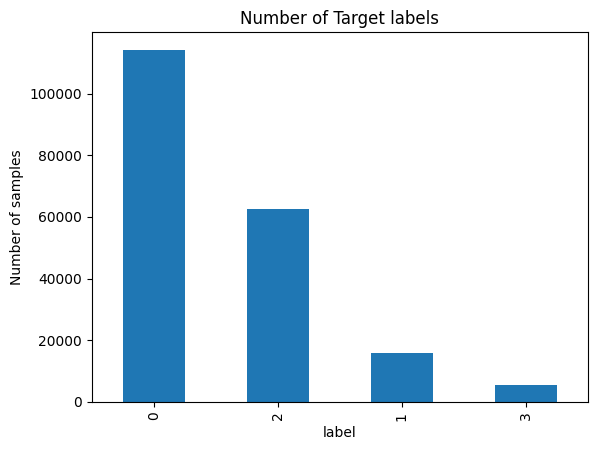

In [41]:
train['label'].value_counts().plot(kind='bar')
plt.title("Number of Target labels")
plt.ylabel("Number of samples")


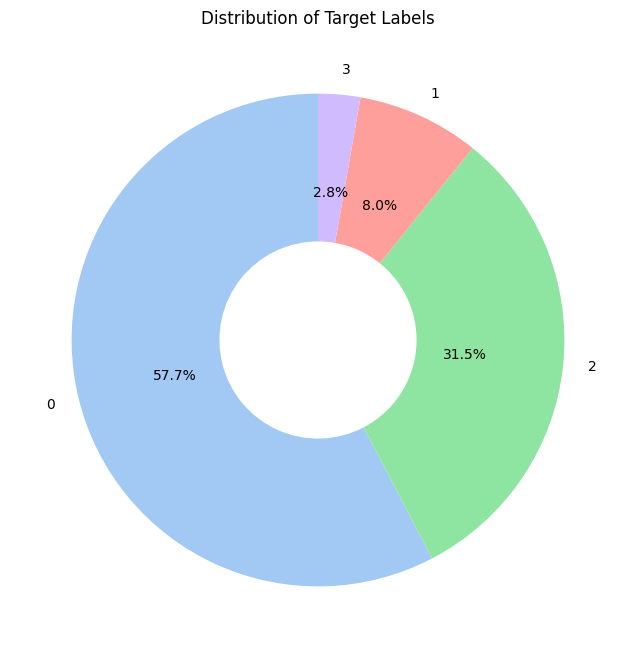

In [42]:
label_distribution = train['label'].value_counts()
plt.figure(figsize=(8,8))
color = sns.color_palette('pastel6')
plt.pie(label_distribution,
        labels=list(label_distribution.index),
        data=train,
        colors=color,
        autopct='%0.1f%%',
        startangle=90,
        wedgeprops=dict(width=0.6))
plt.title("Distribution of Target Labels")
plt.show()

- Label 0: 57.7%
- Label 1: 8.0%
- Label 2: 31.5%
- Label 3: 2.8%

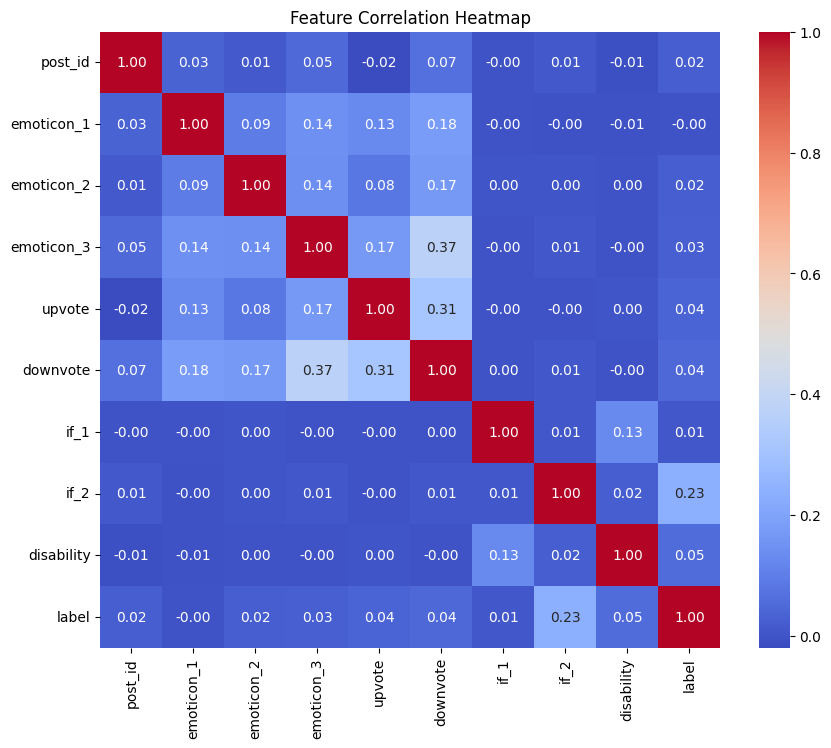

In [43]:
corr = train.corr(numeric_only=True)

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

- Feature are mostly independent.
- emoticon_3 and downvote
    - possible comment with emoticon_3 more receive more downvotes.
- numerical feature have very weak correlation with the label.

In [44]:
train['comment'] = train["comment"].fillna("")

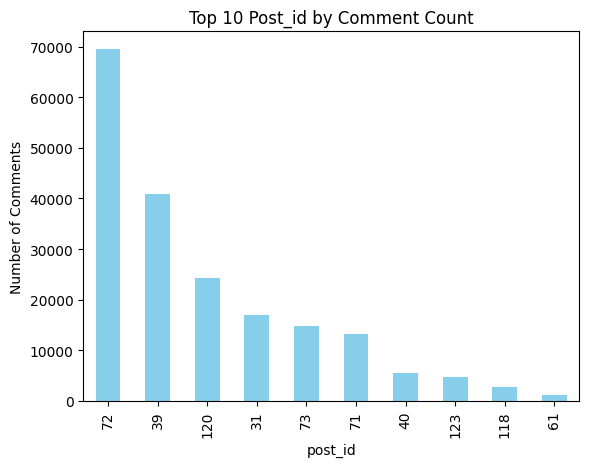

In [45]:
top_posts = train.groupby("post_id").size().sort_values(ascending=False).head(10)

top_posts.plot(kind="bar",color="skyblue")
plt.title("Top 10 Post_id by Comment Count")
plt.ylabel("Number of Comments")
plt.show()

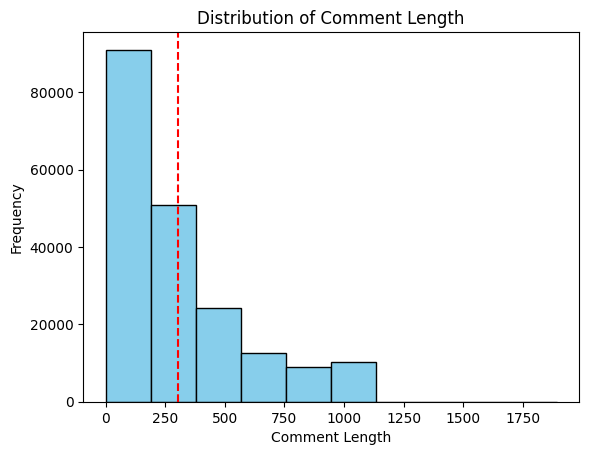

In [46]:
train["comment_length"] = train["comment"].str.len()

plt.hist(train["comment_length"],
         bins=10,
         color='skyblue',
         edgecolor = "black")

# adding line for mean_length 
mean_length = train["comment_length"].mean()
plt.axvline(mean_length,color='red',linestyle='dashed')
plt.title("Distribution of Comment Length")
plt.xlabel("Comment Length")
plt.ylabel("Frequency")
plt.show()

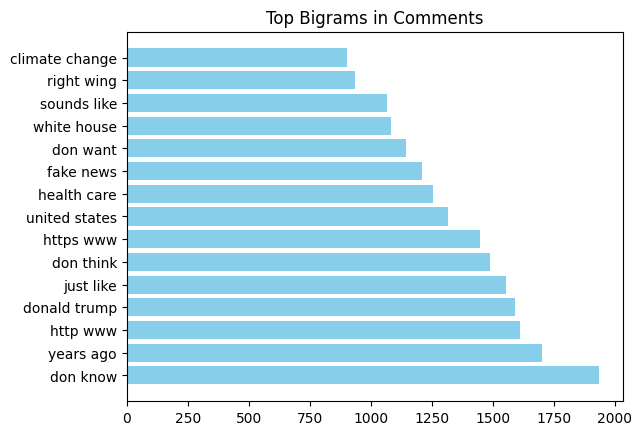

In [47]:
from sklearn.feature_extraction.text import TfidfVectorizer

train['comment'] = train['comment'].fillna("")
vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(2,2), max_features=15)
X = vectorizer.fit_transform(train['comment'])

bigrams = vectorizer.get_feature_names_out()


counts = X.sum(axis=0).A1
#A - convert sparse matrix into dense numpy array 
#A1 - flatten it into 1D array 

bigram_df = pd.DataFrame({"bigram": bigrams, "count": counts}).sort_values(by="count", ascending=False)

plt.barh(bigram_df["bigram"], bigram_df["count"],color="skyblue")
plt.title("Top Bigrams in Comments")
plt.show()

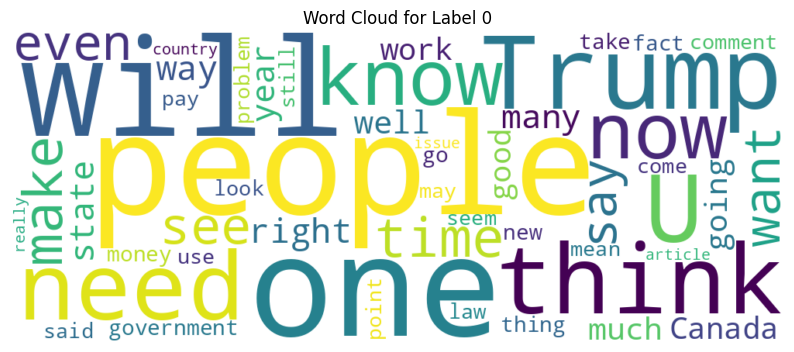

In [48]:
from wordcloud import WordCloud

# Word Cloud for Label 0
text0 = " ".join(train[train['label'] == 0]['comment'].astype(str))
wc0 = WordCloud(width=1000, height=400, background_color="white",max_words=50).generate(text0)
plt.figure(figsize=(10,5))
plt.imshow(wc0, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud for Label 0")
plt.show()

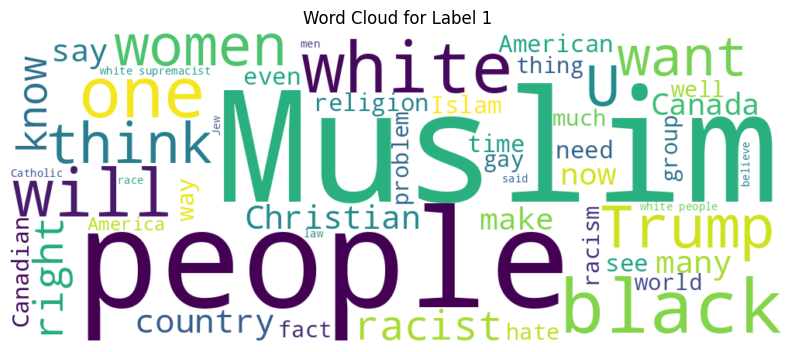

In [49]:
# Word Cloud for Label 1
text1 = " ".join(train[train['label'] == 1]['comment'].astype(str))
wc1 = WordCloud(width=1000, height=400, background_color="white",max_words=50).generate(text1)
plt.figure(figsize=(10,5))
plt.imshow(wc1, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud for Label 1")
plt.show()

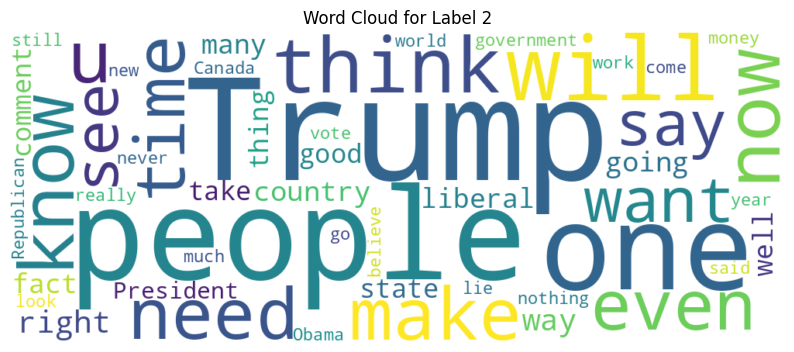

In [50]:
# Word Cloud for Label 2
text2 = " ".join(train[train['label'] == 2]['comment'].astype(str))
wc2 = WordCloud(width=1000, height=400, background_color="white",max_words=50).generate(text2)
plt.figure(figsize=(10,5))
plt.imshow(wc2, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud for Label 2")
plt.show()

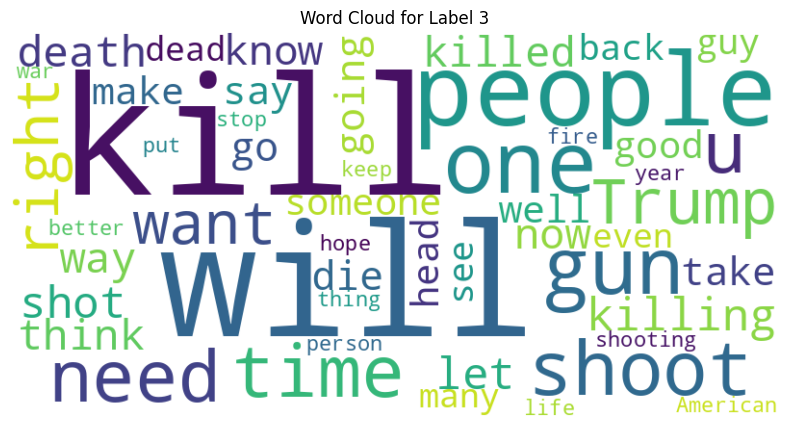

In [51]:
# Word Cloud for Label 3
text3 = " ".join(train[train['label'] == 3]['comment'].astype(str))
wc3 = WordCloud(width=800, height=400, background_color="white",max_words=50).generate(text3)
plt.figure(figsize=(10,5))
plt.imshow(wc3, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud for Label 3")
plt.show()

<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# 4. Feature Engineering and Extraction

</div>

In [52]:
def create_feature(df):
    df = df.copy()
    
    # Text-Based Features

    df["comment"] = df["comment"].fillna("")
    
    df["comment_length"] = df["comment"].apply(len)
    df["word_count"] = df["comment"].apply(lambda x: len(x.split()))
    df["exclamation_count"] = df["comment"].apply(lambda x: x.count("!"))
    df["question_count"] = df["comment"].apply(lambda x: x.count("?"))
    
    df["capital_ratio"] = df["comment"].apply(
        lambda x: sum(1 for c in x if c.isupper()) / (len(x) + 1)
    )
    
    # comment base feature 
    df['comment_length'] = train['comment'].apply(len)
    df['word_count'] = df['comment'].apply(lambda x: len(x.split()))
    
    df["created_date"] = pd.to_datetime(df["created_date"], errors="coerce")
    
    df["hour"] = df["created_date"].dt.hour
    df["day_of_week"] = df["created_date"].dt.dayofweek
    df["month"] = df["created_date"].dt.month
    
    
    # Weekend flag
    df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)
    
    
    #Engagement feature 
    df['total_votes'] =df['upvote'] + df['downvote']
    
    
    #Emoticon feature 
    df['total_emoticons'] = df['emoticon_1'] + df['emoticon_2']+df['emoticon_3']
    del df["created_date"]
    
    return df
    

In [53]:
train = create_feature(train)
test = create_feature(test)

In [54]:
import re

def normalize_text(text):

    # replace URLs
    text = re.sub(r'http\S+|www\S+|https\S+', 'url', text)

    # remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

train['comment'] = train['comment'].apply(normalize_text)
test['comment']= test['comment'].apply(normalize_text)

<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# #.Split Data

</div>

In [55]:
X = train.drop(columns=['label'])
y = train['label']

X_train,X_test, y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y
)

<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# 4. Data Preprocessing

</div>

In [56]:
# filling missing categorical value 
cat_cols= ['race','religion','gender']

for col in cat_cols:
    train[col] = train[col].fillna("unknown")
    test[col] = test[col].fillna("unknown")
    train[col] = train[col].astype('category')
    test[col] = test[col].astype('category')

# convert disability to int
train['disability'] = train['disability'].astype(int)
test['disability'] = test['disability'].astype(int)


In [57]:
text = 'comment'
numerical = X.select_dtypes(exclude=['object','category']).columns
categorical_col = ['race', 'religion', 'gender']

In [58]:
# now lets create pipeline after handling this all stuff 

word_tfidf = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1,2),
    max_features=23000,
    min_df=3,
    max_df=0.9,
    sublinear_tf=True,
    stop_words="english"
)

char_tfidf = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3,5),
    max_features=15000
)

text_pipeline = FeatureUnion(
    transformer_list=[
        ('word' , word_tfidf),
        ('char' , char_tfidf)
    ]
)




num_pipeline = Pipeline([
("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, numerical),
    ("cat", cat_pipeline, categorical_col),
    ("text", text_pipeline, text)
])

<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# 5. Model Building & Training

</div>

<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## Model1: Linearsvc

</div>

In [59]:
model1 = Pipeline([
    ('preprocessing', preprocessor),
    ('model',  LinearSVC(max_iter=800,
                                  C=0.5)
     )
     
])
model1

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  Index(['post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote',
       'downvote', 'if_1', 'if_2', 'disability', 'comment_length',
       'word_count', 'exclamation_count', 'question_count', 'capital_ratio',
       'hour', 'day_of_week', 'month', 'is_weekend', 'tot...
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['race', 'religion',
                                                   'gender']),
                                                 ('text',
                                                  FeatureUnion(transformer_list=[('word',
                                                                                  TfidfVectorizer(max_df=0.9,
                                                                                                  max_features=23000,
                                                                                                  min_df=3,
                                                                                                  ngram_range=(1,
                                                                                                               2),
                                                                                                  stop_words='english',
                                                                                                  sublinear_tf=True)),
                                                                                 ('char',
                                                                                  TfidfVectorizer(analyzer='char_wb',
                                                                                                  max_features=15000,
                                                                                                  ngram_range=(3,
                                                                                                               5)))]),
                                                  'comment')])),
                ('model', LinearSVC(C=0.5, max_iter=800))])

In [60]:
model1.fit(X_train, y_train)
y_pred = model1.predict(X_train)

print("Training f1 score for model1:", f1_score(y_train, y_pred,average='macro'))


# Training f1 score for model1: 0.8225403571693088

Training f1 score for model1: 0.8225403571693088


In [61]:
y_pred1 = model1.predict(X_test)
model1_score = f1_score(y_test, y_pred1,average='macro')
model1_score  #0.6874633234635525

0.6874633234635525

In [62]:
print(classification_report(y_test, y_pred1))

              precision    recall  f1-score   support

           0       0.82      0.90      0.85     22835
           1       0.72      0.64      0.68      3183
           2       0.80      0.71      0.75     12488
           3       0.66      0.36      0.47      1094

    accuracy                           0.80     39600
   macro avg       0.75      0.65      0.69     39600
weighted avg       0.80      0.80      0.80     39600



<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## Model2: LogisticRegression

</div>

In [63]:
model2 = Pipeline([
    ('preprocessing', preprocessor),
    ('model2',LogisticRegression(max_iter=400,
                      class_weight='balanced',
                      C=1,
                      random_state=42))
     
])
model2

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  Index(['post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote',
       'downvote', 'if_1', 'if_2', 'disability', 'comment_length',
       'word_count', 'exclamation_count', 'question_count', 'capital_ratio',
       'hour', 'day_of_week', 'month', 'is_weekend', 'tot...
                                                   'gender']),
                                                 ('text',
                                                  FeatureUnion(transformer_list=[('word',
                                                                                  TfidfVectorizer(max_df=0.9,
                                                                                                  max_features=23000,
                                                                                                  min_df=3,
                                                                                                  ngram_range=(1,
                                                                                                               2),
                                                                                                  stop_words='english',
                                                                                                  sublinear_tf=True)),
                                                                                 ('char',
                                                                                  TfidfVectorizer(analyzer='char_wb',
                                                                                                  max_features=15000,
                                                                                                  ngram_range=(3,
                                                                                                               5)))]),
                                                  'comment')])),
                ('model2',
                 LogisticRegression(C=1, class_weight='balanced', max_iter=400,
                                    random_state=42))])

In [64]:
model2.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  Index(['post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote',
       'downvote', 'if_1', 'if_2', 'disability', 'comment_length',
       'word_count', 'exclamation_count', 'question_count', 'capital_ratio',
       'hour', 'day_of_week', 'month', 'is_weekend', 'tot...
                                                   'gender']),
                                                 ('text',
                                                  FeatureUnion(transformer_list=[('word',
                                                                                  TfidfVectorizer(max_df=0.9,
                                                                                                  max_features=23000,
                                                                                                  min_df=3,
                                                                                                  ngram_range=(1,
                                                                                                               2),
                                                                                                  stop_words='english',
                                                                                                  sublinear_tf=True)),
                                                                                 ('char',
                                                                                  TfidfVectorizer(analyzer='char_wb',
                                                                                                  max_features=15000,
                                                                                                  ngram_range=(3,
                                                                                                               5)))]),
                                                  'comment')])),
                ('model2',
                 LogisticRegression(C=1, class_weight='balanced', max_iter=400,
                                    random_state=42))])

In [65]:
y_pred_lr_train = model2.predict(X_train)
print("Logistic Regression f1_score for train:", f1_score(y_train, y_pred_lr_train,average='macro'))

Logistic Regression f1_score for train: 0.8795269544516673


In [66]:
y_pred_lr = model2.predict(X_test)
model2_score = f1_score(y_test, y_pred_lr,average='macro')
model2_score

0.7990202066197396

In [67]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.98      0.93      0.96     22835
           1       0.68      0.85      0.75      3183
           2       0.88      0.87      0.88     12488
           3       0.50      0.79      0.61      1094

    accuracy                           0.90     39600
   macro avg       0.76      0.86      0.80     39600
weighted avg       0.91      0.90      0.91     39600



In [68]:
# confusion matrix 
confusion_matrix(y_test, y_pred_lr)

array([[21195,   420,   924,   296],
       [   19,  2716,   351,    97],
       [  297,   816, 10895,   480],
       [   18,    66,   151,   859]])

<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## Model3 -Naive Bayes

</div>

In [69]:
from sklearn.preprocessing import MinMaxScaler

In [70]:
num_pipeline = Pipeline([
("scaler", MinMaxScaler())
])

preprocessor3 = ColumnTransformer([
    ("num", num_pipeline, numerical),
    ("cat", cat_pipeline, categorical_col),
    ("text", text_pipeline, text)
])

In [71]:
from sklearn.naive_bayes import MultinomialNB
model3 = Pipeline(
    [
        ('preprocessing' , preprocessor3),
        ('model',MultinomialNB())
    ]
)

In [72]:
model3.fit(X_train, y_train)
y_pred = model3.predict(X_train)
print("Training f1 score for model3:", f1_score(y_train, y_pred,average='macro'))

#Training f1 score for model3: 0.6062583999341247

Training f1 score for model3: 0.6062583999341247


In [73]:
y_pred3 = model3.predict(X_test)
model3_score =  f1_score(y_test, y_pred3,average='macro')
model3_score

# 0.5868895764395881

0.5868895764395881

In [74]:
print(classification_report(y_test, y_pred3))

              precision    recall  f1-score   support

           0       0.79      0.80      0.80     22835
           1       0.46      0.81      0.59      3183
           2       0.71      0.61      0.65     12488
           3       0.64      0.20      0.31      1094

    accuracy                           0.72     39600
   macro avg       0.65      0.60      0.59     39600
weighted avg       0.74      0.72      0.72     39600




print(classification_report(y_test, y_pred3))
              precision    recall  f1-score   support

           0       0.79      0.80      0.80     22835
           1       0.46      0.81      0.59      3183
           2       0.71      0.61      0.65     12488
           3       0.64      0.20      0.31      1094

    accuracy                           0.72     39600
   macro avg       0.65      0.60      0.59     39600
weighted avg       0.74      0.72      0.72     39600

<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# 6. Hyperparameter Tuning

</div>

In [75]:
from sklearn.model_selection import GridSearchCV , RandomizedSearchCV

<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## Model1 - Linearsvc

</div>

In [76]:
# param_dist = {
    
#     "model__C" : [0.5,1],
#     "model__max_iter": [800,1000,1200]
# }


In [77]:
# from sklearn.model_selection import GridSearchCV


# grid = GridSearchCV(estimator=model1, param_grid=param_dist, cv=3, scoring='f1', n_jobs=-1)

# grid.fit(X_train, y_train)

# print(grid.best_params_)

{'model__C': 0.5, 'model__max_iter': 800, 'model__tol': 0.0001}


<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## Model2: Logistic Regression

</div>

In [78]:
# param_dist = {
#      "model2__C" : [0.5,1,2],
#     "model2__max_iter": [500,1000,12000]
# }
# grid2 = RandomizedSearchCV(estimator=model2,
#                     param_distributions=param_dist,
#                     cv=3,
#                     n_iter = 5,
#                     scoring='f1')

# grid2.fit(X_train, y_train)

# print(grid2.best_params_)


<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## Model3:navie Bayes

</div>

In [79]:
# param_dist = {
#     "model__alpha" : [0.01.0.1]
# }

In [80]:
# grid3 = GridSearchCV(estimator=model3,
#                     param_grid=param_dist,
#                     cv=3,
#                     scoring='f1')

# grid3.fit(X_train, y_train)

# print(grid3.best_params_)
# print(grid3.best_score_)

<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# 7.Analysis

</div>

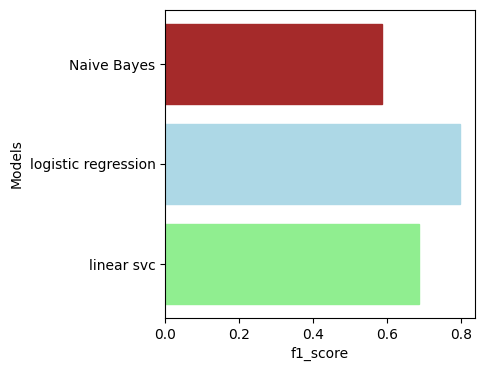

In [81]:
names = ['linear svc','logistic regression','Naive Bayes']
score = [model1_score, model2_score, model3_score]

plt.figure(figsize=(4,4))
graph = plt.barh(names,score)
plt.xlabel('f1_score')
plt.ylabel('Models')

graph[0].set_color('lightgreen')
graph[1].set_color('lightblue')
graph[2].set_color('brown')

plt.show()


<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# 8.Submission

</div>

In [82]:
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score



xgb = XGBClassifier(
    n_estimators=25,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    random_state=42
)

lr = LogisticRegression(
    max_iter=1100,
    C=2,
    class_weight="balanced"
) 


stack_model = StackingClassifier(
    estimators=[
        ("xgb", xgb),
        ("lr", lr)
    ],
    final_estimator=LogisticRegression(),
    stack_method="predict_proba",
    n_jobs=1
)
pipeline = Pipeline([
    ("model", stack_model)
])

In [ ]:
X_preprocessed =preprocessor.fit_transform(X)
test_preprocessed =preprocessor.transform(test)



pipeline.fit(X_preprocessed, y)
prediction = pipeline.predict(test_preprocessed)


In [ ]:
test.shape

In [ ]:
print(classification_report(y, prediction))

In [ ]:
submission = pd.DataFrame({
    "ID": sample["ID"],
    "label": prediction
})

submission.to_csv("submission.csv", index=False)
submission.head()